In [72]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("combined_chronic_delays.csv")

# Convert numerical columns
numeric_cols = [
    "total_operations",
    "delayed_operations",
    "percentage_delay",
    "average_delay_minutes",
    "departure_time"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Extract departure hour from HHMM format
df["departure_hour"] = df["departure_time"] // 100
df.loc[~df["departure_hour"].between(0, 23),
       "departure_hour"] = np.nan

# Separate origin and destination airports
df[["origin", "destination"]] = (
    df["origin_destination"].str.split("-", n=1, expand=True)
)

# Month order
month_order = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

df["month_short"] = df["month"].astype(str).str[:3].str.title()

sns.set_theme(style="whitegrid")


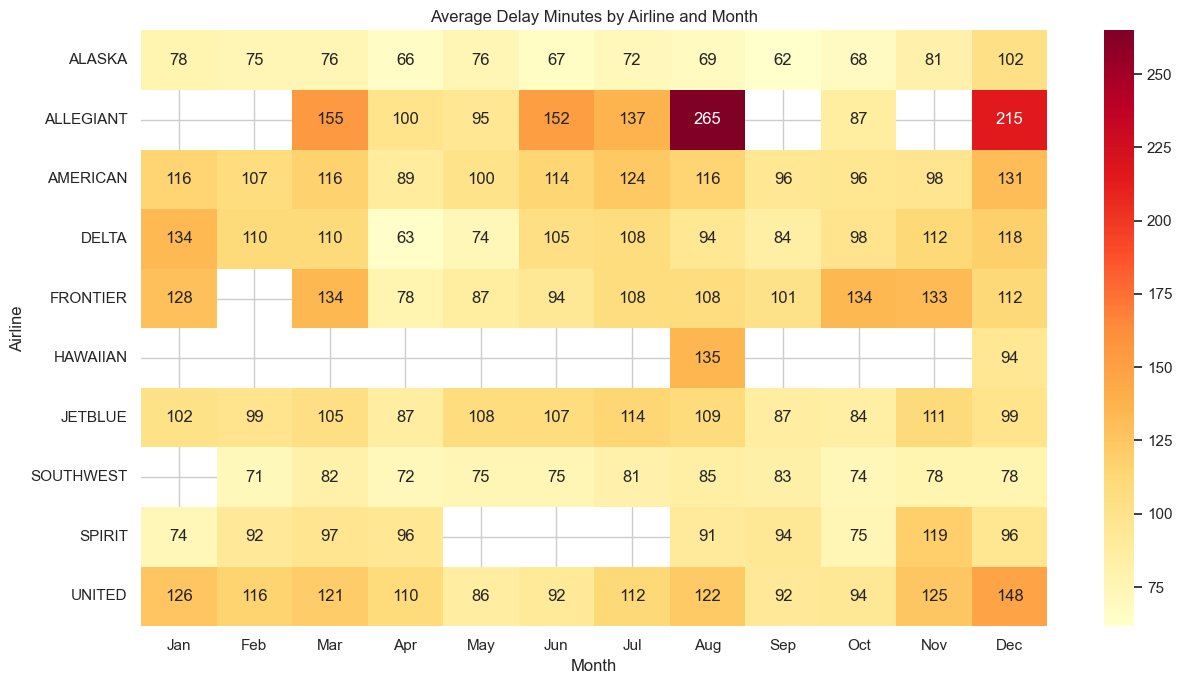

In [74]:
heatmap_data = df.pivot_table(
    index="marketing_carrier_name",
    columns="month_short",
    values="average_delay_minutes",
    aggfunc="mean"
)

heatmap_data = heatmap_data.reindex(columns=month_order)

plt.figure(figsize=(13, 7))
sns.heatmap(
    heatmap_data,
    cmap="YlOrRd",
    annot=True,
    fmt=".0f"
)

plt.title("Average Delay Minutes by Airline and Month")
plt.xlabel("Month")
plt.ylabel("Airline")
plt.tight_layout()
plt.show()


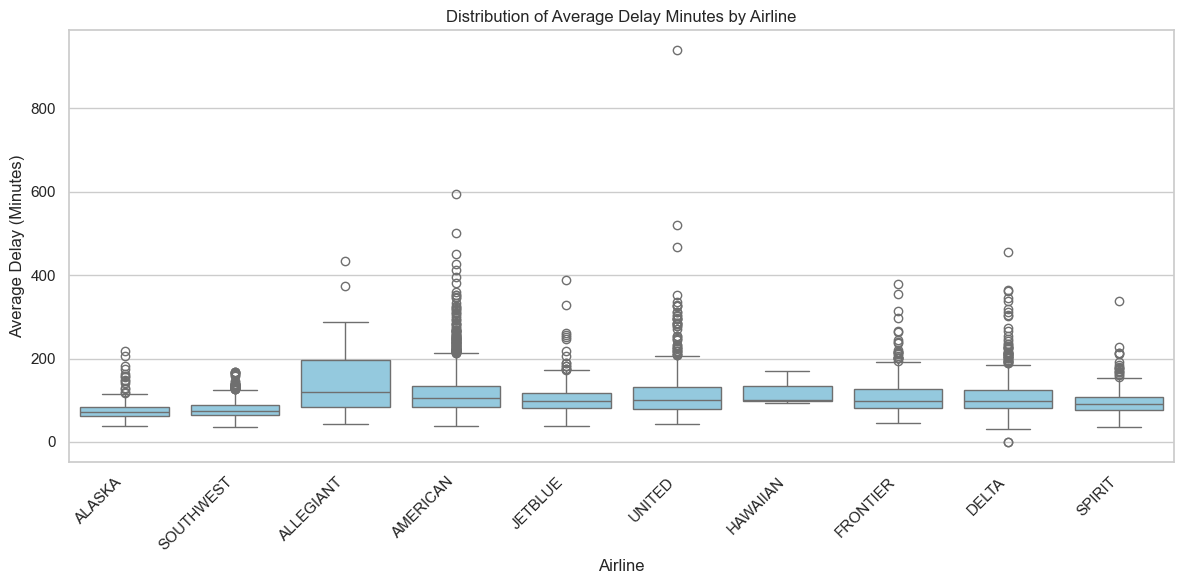

In [76]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="marketing_carrier_name",
    y="average_delay_minutes",
    color="skyblue"
)

plt.xticks(rotation=45, ha="right")
plt.title("Distribution of Average Delay Minutes by Airline")
plt.xlabel("Airline")
plt.ylabel("Average Delay (Minutes)")
plt.tight_layout()
plt.show()


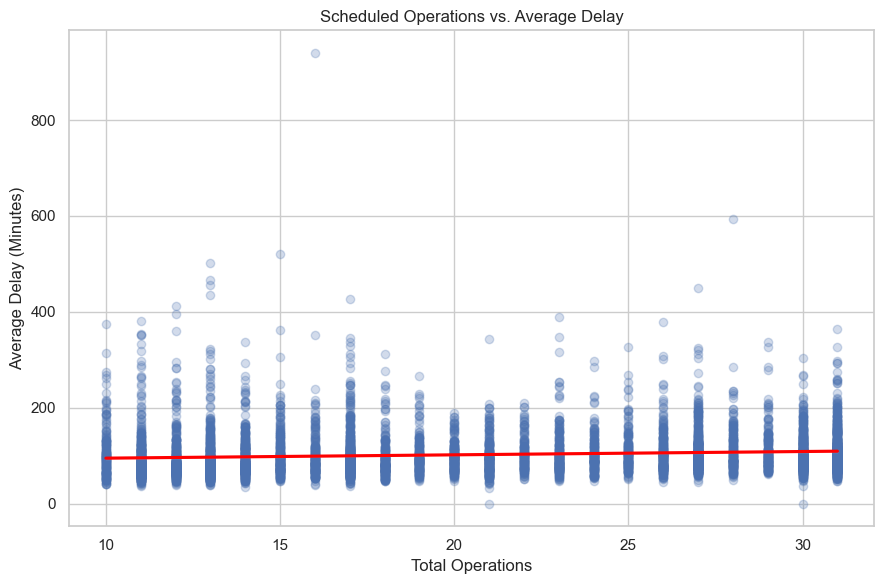

                       total_operations  average_delay_minutes
total_operations               1.000000               0.104361
average_delay_minutes          0.104361               1.000000


In [78]:
plt.figure(figsize=(9, 6))

sns.regplot(
    data=df,
    x="total_operations",
    y="average_delay_minutes",
    scatter_kws={"alpha": 0.25},
    line_kws={"color": "red"}
)

plt.title("Scheduled Operations vs. Average Delay")
plt.xlabel("Total Operations")
plt.ylabel("Average Delay (Minutes)")
plt.tight_layout()
plt.show()

# Correlation
print(
    df[["total_operations", "average_delay_minutes"]]
    .corr()
)


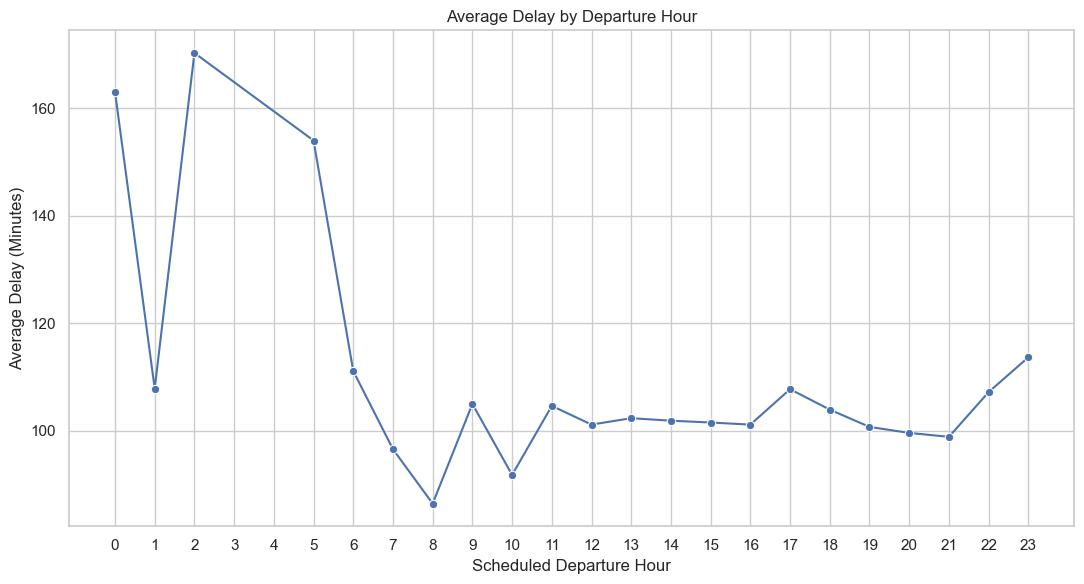

    departure_hour        mean  count
0              0.0  163.080000      3
1              1.0  107.856667      6
2              2.0  170.270000      1
3              5.0  153.990000      8
4              6.0  111.125789     19
5              7.0   96.593871     62
6              8.0   86.474321     81
7              9.0  105.014651     86
8             10.0   91.817213    122
9             11.0  104.645942    138
10            12.0  101.170450    200
11            13.0  102.363197    244
12            14.0  101.893904    356
13            15.0  101.557300    437
14            16.0  101.165614    586
15            17.0  107.753356    888
16            18.0  103.953151    933
17            19.0  100.741413    998
18            20.0   99.626008    794
19            21.0   98.894828    495
20            22.0  107.211648    267
21            23.0  113.683929     28


In [80]:
hourly = (
    df.groupby("departure_hour")["average_delay_minutes"]
    .agg(["mean", "count"])
    .reset_index()
)

plt.figure(figsize=(11, 6))

sns.lineplot(
    data=hourly,
    x="departure_hour",
    y="mean",
    marker="o"
)

plt.xticks(range(0, 24))
plt.title("Average Delay by Departure Hour")
plt.xlabel("Scheduled Departure Hour")
plt.ylabel("Average Delay (Minutes)")
plt.tight_layout()
plt.show()

print(hourly)


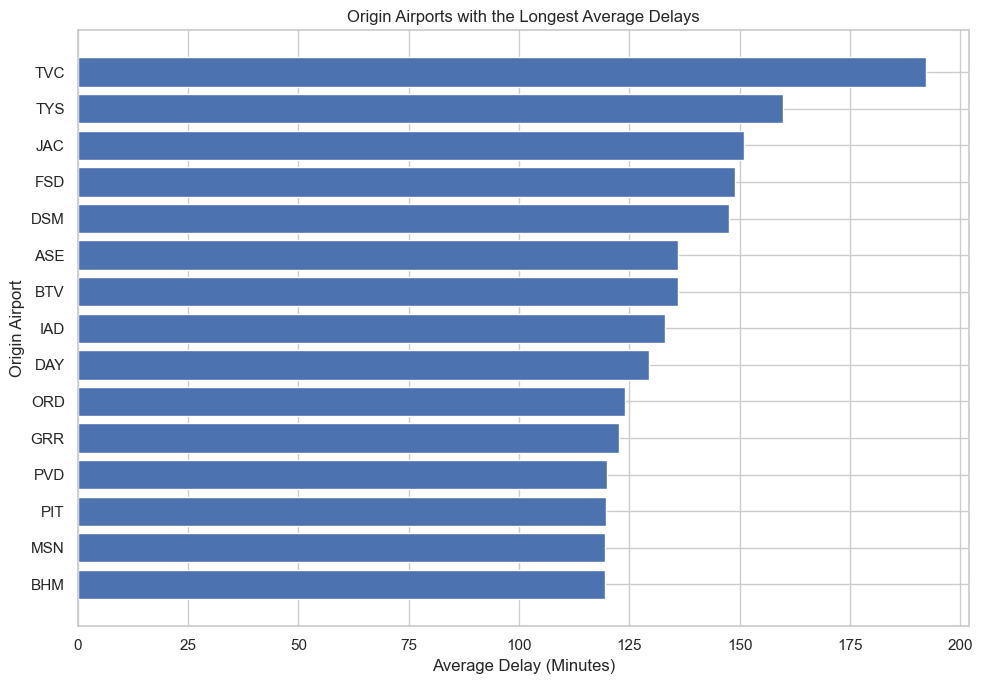

In [82]:
airport_delays = (
    df.groupby("origin")
    .agg(
        avg_delay=("average_delay_minutes", "mean"),
        flights=("average_delay_minutes", "count")
    )
    .query("flights >= 10")
    .sort_values("avg_delay", ascending=False)
    .head(15)
    .sort_values("avg_delay")
)

plt.figure(figsize=(10, 7))

plt.barh(
    airport_delays.index,
    airport_delays["avg_delay"]
)

plt.title("Origin Airports with the Longest Average Delays")
plt.xlabel("Average Delay (Minutes)")
plt.ylabel("Origin Airport")
plt.tight_layout()
plt.show()


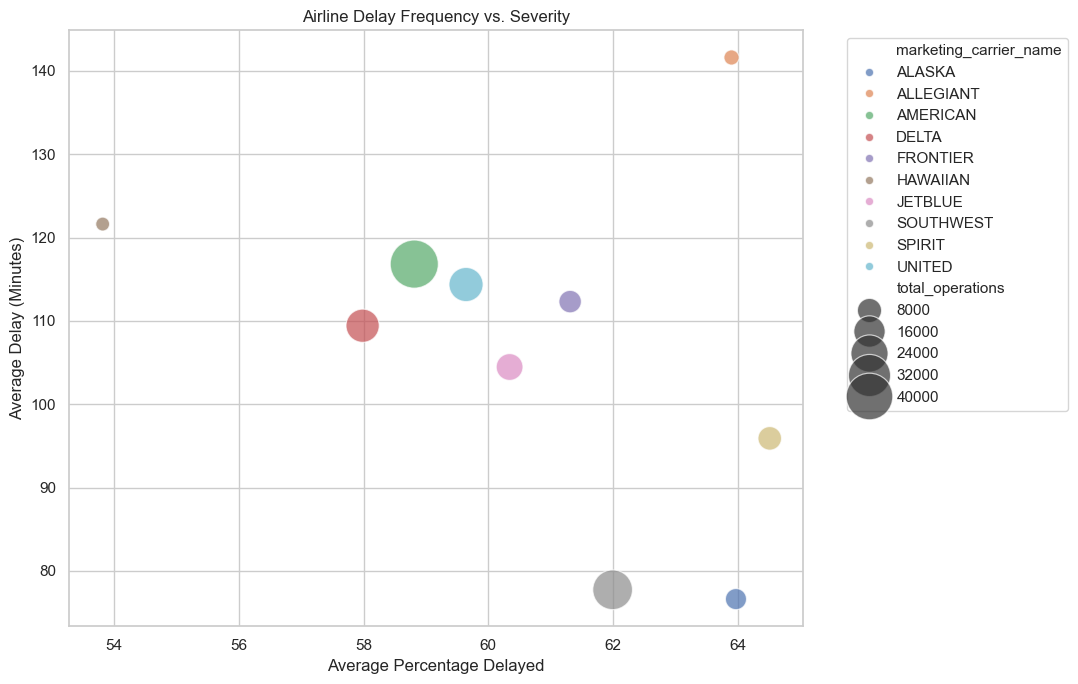

In [84]:
airline_summary = (
    df.groupby("marketing_carrier_name")
    .agg(
        avg_delay=("average_delay_minutes", "mean"),
        avg_pct_delay=("percentage_delay", "mean"),
        total_operations=("total_operations", "sum")
    )
    .reset_index()
)

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=airline_summary,
    x="avg_pct_delay",
    y="avg_delay",
    size="total_operations",
    hue="marketing_carrier_name",
    sizes=(100, 1200),
    alpha=0.7
)

plt.title("Airline Delay Frequency vs. Severity")
plt.xlabel("Average Percentage Delayed")
plt.ylabel("Average Delay (Minutes)")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()
